## Mission 3 (v0.4) — KLUE-RoBERTa(sqrt) + KcELECTRA(sqrt) 앙상블

- 입력: 신고자·119대원 대화 **전사 텍스트** / 출력: 공식 9개 증상 (멀티라벨) / 제출 CSV: `[label file name], [symptom]`
- **구성**: `klue/roberta-base` + `beomi/KcELECTRA-base-v2022`를 각각 **pos_weight = sqrt(neg/pos)** 로 학습(seed 42·123·2026) → 확률 평균 앙상블
- 앙상블 규칙: 같은 백본의 seed끼리 평균 → 백본 두 개를 **동일 가중(50:50)** 으로 평균 → threshold 0.5

### 규정 준수 요약
- Decision Threshold는 **모든 class에 0.5 고정**. class별 threshold, Train/Validation/OOF 기반 threshold 탐색은 하지 않음
- pos_weight는 **Train의 양성/음성 비율로만 계산하는 사전 고정 규칙(sqrt(neg/pos))**. 값(지수·배율)을 바꿔가며 탐색하지 않음
- 앙상블 가중치(백본 50:50)도 사전 고정. Validation으로 탐색하지 않음
- Validation은 **평가와 best epoch 선택(macro-F1)에만** 사용. 학습에 넣지 않음
- 외부 데이터/API 없음. 공개 pretrained 모델을 받아 자체 fine-tuning만 사용
- 오프라인 채점 대비: 모든 모델의 가중치·tokenizer·config를 로컬 폴더(제출 패키지)에 저장하고 `local_files_only=True`로만 불러옴
- 제출 시 명시: 파라미터 수(앙상블 전체), 컴퓨팅 환경, Validation batch size, 추론시간 → 11번 셀 출력 / 6b 결과표

### 끊겨도 이어서 실행하는 방법 (모든 셀 공통)
1. 런타임이 끊기면 **새 세션에서 "런타임 → 모두 실행"** 을 누릅니다. (Drive 인증 팝업은 직접 승인해야 합니다)
2. 모든 셀은 다시 실행해도 안전하게 만들었습니다.
   - 환경/함수 정의 셀: 그대로 다시 실행
   - 데이터 셀: Drive의 파싱 캐시(`cache/parsed_*.pkl`)가 있으면 JSON 복사·파싱 없이 바로 불러옴. 처음 한 번만 JSON을 복사하고, 복사가 덜 됐으면 개수를 검사해 멈춘 뒤 다시 실행하면 이어서 복사
   - 학습 셀: 끝난 실행은 건너뛰고, 진행 중이던 실행은 마지막 저장 지점(**`ckpt_every_steps`스텝 단위 + epoch 끝**)부터 이어서 학습
   - 결과·앙상블·패키지·테스트 셀: Drive의 결과 파일만 읽고 쓰므로 몇 번을 실행해도 같은 결과
3. 이어하기 파일(`_last.pt`)은 모델 + optimizer 상태라 1.3~1.6GB입니다. Drive 용량을 확인하세요. 저장이 너무 느리면 `CONFIG["ckpt_every_steps"]`를 키우거나 0(= epoch 끝에서만 저장)으로 두세요.
4. 처음부터 다시 하고 싶은 실행은 `ckpt/{이름}_last.pt`와 `history/{이름}_done.json`을 지우세요.


### 0. GPU 확인

In [1]:
!nvidia-smi


Mon Oct 12 14:49:20 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### 1. 환경 설정

In [3]:
# ===== 환경 설정 =====
IS_DRIVE = True  # Google Drive 마운트를 쓰면 True

if IS_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')

!pip install -q transformers scikit-learn

import os, json, shutil, random, time, uuid, math, gc
os.environ["TOKENIZERS_PARALLELISM"] = "false"  # DataLoader worker에서 토크나이저 경고/교착 방지
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import f1_score, accuracy_score
import transformers
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print(f"device={device}, GPU={GPU_NAME}, torch={torch.__version__}, transformers={transformers.__version__}")

SEEDS = [42, 123, 2026]  # 팀 공통 seed

DRIVE_ROOT = ("/content/drive/MyDrive/projects/AI-DCC/mission1-data" if IS_DRIVE
              else os.path.join(os.path.expanduser("~"), "Downloads", "mission1-data"))

# 팀 공식 9개 라벨 (순서 고정) / 팀 공지의 Training 클래스별 양성 수 (파싱이 맞는지 확인용)
TEAM_LABELS = ["고열", "구토", "두통", "복통", "어지러움", "열상", "오심", "전신쇠약", "호흡곤란"]
TEAM_TRAIN_POS = {"복통": 6771, "어지러움": 6334, "전신쇠약": 5310, "고열": 5186, "구토": 4463,
                  "호흡곤란": 3927, "열상": 3465, "오심": 3341, "두통": 2905}

# 백본 설정 (모두 공개 pretrained). epochs는 상한이고 best epoch은 Validation macro-F1로 선택(patience로 조기 종료)
# KLUE-RoBERTa는 팀에서 보고된 설정(lr 2e-5, warmup 10%, epochs 8, patience 3)을 따름. 분류 head는 HF 기본 head
BACKBONES = {
    "klue_roberta_base": {"hf_id": "klue/roberta-base",              "batch_size": 16, "lr": 2e-5, "warmup_ratio": 0.10, "epochs": 8, "patience": 3},
    "kcelectra":         {"hf_id": "beomi/KcELECTRA-base-v2022",      "batch_size": 16, "lr": 3e-5, "warmup_ratio": 0.06, "epochs": 8, "patience": 3},
}
ENSEMBLE_BACKBONES = ["klue_roberta_base", "kcelectra"]  # 앙상블 구성 (백본 동일 가중)
RUN_CONFIG_NAME = "sqrt"                                  # 파일명에 들어가는 설정 이름

CONFIG = {
    # 미션3은 텍스트만 쓰므로 라벨링(JSON)만 사용. val_audio_root는 inference.py CLI 호환용으로만 넘김
    "train_label_root": os.path.join(DRIVE_ROOT, "Training", "2.라벨링데이터", "TL_서울_구급"),
    "val_label_root":   os.path.join(DRIVE_ROOT, "Validation", "2.라벨링데이터", "VL_서울_구급"),
    "val_audio_root":   os.path.join(DRIVE_ROOT, "Validation", "1.원천데이터", "VS_서울_구급"),
    "local_json_dir": "/content/m3_local_json",
    "expected_n": {"train": 29200, "val": 3640},   # JSON 복사/파싱이 덜 됐는지 검사하는 기준

    # 팀 공유 Drive 폴더 (모델 / 확률 CSV / history / 캐시 / 제출 패키지가 저장되는 곳)
    "drive_share_root": "/content/drive/MyDrive/DCC/mission3_v4",  # TODO: 팀 공유 폴더 경로 확인

    "symptom_labels": TEAM_LABELS,
    "max_length": 512,     # 초과분은 뒤쪽이 잘림 (512 초과 콜 0.4%)
    "train_frac": 1.0,     # 1.0 미만이면 학습 데이터 일부만 사용(빠른 점검용). Validation은 항상 전체
    "weight_decay": 0.01,
    "ckpt_every_steps": 1000,  # 이어하기 저장 간격(스텝). 0이면 epoch 끝에서만 저장
}

CONFIG["ckpt_dir"] = os.path.join(CONFIG["drive_share_root"], "ckpt")
CONFIG["preds_dir"] = os.path.join(CONFIG["drive_share_root"], "preds")
CONFIG["history_dir"] = os.path.join(CONFIG["drive_share_root"], "history")
CONFIG["cache_dir"] = os.path.join(CONFIG["drive_share_root"], "cache")
for d in [CONFIG["ckpt_dir"], CONFIG["preds_dir"], CONFIG["history_dir"], CONFIG["cache_dir"]]:
    os.makedirs(d, exist_ok=True)


Mounted at /content/drive
device=cuda, GPU=Tesla T4, torch=2.11.0+cu130, transformers=5.18.0


### 2. 데이터 준비 (JSON 복사 → 파싱 → Drive 캐시)

In [5]:
# ===== 처음 한 번만 JSON을 복사·파싱하고 Drive에 캐시. 재접속 후에는 캐시를 바로 불러옴 =====
from concurrent.futures import ThreadPoolExecutor, as_completed

def copy_one_file(src_path, dst_path):
    if os.path.exists(dst_path) and os.path.getsize(dst_path) == os.path.getsize(src_path):
        return True, None
    tmp_path = f"{dst_path}.{uuid.uuid4().hex}.part"  # 스레드별 고유 임시 파일명 -> 이름 충돌 방지
    try:
        shutil.copy(src_path, tmp_path)
        os.rename(tmp_path, dst_path)
        return True, None
    except OSError as e:
        return False, str(e)

def copy_json_tree(src_root, dst_root, max_workers=16):
    os.makedirs(dst_root, exist_ok=True)
    tasks = []
    for dirpath, _, filenames in os.walk(src_root):
        dst_dir = os.path.join(dst_root, os.path.relpath(dirpath, src_root))
        os.makedirs(dst_dir, exist_ok=True)
        for fname in filenames:
            tasks.append((os.path.join(dirpath, fname), os.path.join(dst_dir, fname)))
    if len(tasks) == 0:
        raise RuntimeError(f"{src_root} 에서 파일을 하나도 찾지 못했습니다. 이 셀을 다시 실행해보세요.")
    print(f"{src_root}: {len(tasks)}개 파일 복사 시작 (병렬 {max_workers}개)")
    failed = 0
    with ThreadPoolExecutor(max_workers=max_workers) as ex:
        futures = [ex.submit(copy_one_file, s, d) for s, d in tasks]
        for i, fu in enumerate(as_completed(futures)):
            ok, _ = fu.result()
            failed += (not ok)
            if (i + 1) % 5000 == 0:
                print(f"  {i + 1}/{len(tasks)} 완료")
    return len(tasks), failed

def build_text(utterances):
    """startAt 순 정렬 -> text만 공백으로 연결 (팀 통일안: 화자 태그 없음, 전사 텍스트 외 필드 미사용)"""
    parts = [(u.get("text") or "").strip() for u in sorted(utterances, key=lambda u: u.get("startAt", 0))]
    return " ".join(p for p in parts if p)

def parse_json(path):
    with open(path, "r", encoding="utf-8") as f:
        meta = json.load(f)
    symptoms = meta.get("symptom") or []   # 정답이므로 입력에는 쓰지 않음
    if isinstance(symptoms, str):
        symptoms = [symptoms]
    return {"file_name": os.path.basename(path),
            "text": build_text(meta.get("utterances", meta.get("utterences", []))),
            "symptoms": symptoms}

def build_df(local_root):
    rows = []
    for dirpath, _, filenames in os.walk(local_root):
        for fname in filenames:
            if fname.endswith(".json"):
                rows.append(parse_json(os.path.join(dirpath, fname)))
    df = pd.DataFrame(rows).sort_values("file_name").reset_index(drop=True)  # 순서를 항상 같게
    df.insert(0, "call_id", [os.path.splitext(f)[0] for f in df["file_name"]])  # 확장자 뺀 파일명 (팀 약속)
    return df

def load_or_build(split):
    cache_path = os.path.join(CONFIG["cache_dir"], f"parsed_{split}.pkl")
    if os.path.exists(cache_path):
        print(f"[{split}] 캐시에서 불러옴: {cache_path}")
        return pd.read_pickle(cache_path)
    local = os.path.join(CONFIG["local_json_dir"], split)
    copy_json_tree(CONFIG[f"{split}_label_root"], local)
    df = build_df(local)
    if len(df) != CONFIG["expected_n"][split]:
        raise RuntimeError(f"[{split}] JSON이 {len(df)}개만 읽혔습니다 (기대 {CONFIG['expected_n'][split]}). "
                           "이 셀을 다시 실행하세요 (이미 복사된 파일은 건너뛰고 이어서 복사합니다)")
    tmp = cache_path + ".tmp"
    df.to_pickle(tmp)
    os.replace(tmp, cache_path)  # 개수가 맞을 때만 캐시 저장 (불완전한 캐시가 남지 않음)
    print(f"[{split}] 파싱 후 캐시 저장: {cache_path}")
    return df

train_df = load_or_build("train")
val_df = load_or_build("val")
print(f"train: {len(train_df)}건, val: {len(val_df)}건 | 빈 텍스트 콜: train {(train_df['text'] == '').sum()}, val {(val_df['text'] == '').sum()}")


[train] 캐시에서 불러옴: /content/drive/MyDrive/DCC/mission3_v4/cache/parsed_train.pkl
[val] 캐시에서 불러옴: /content/drive/MyDrive/DCC/mission3_v4/cache/parsed_val.pkl
train: 29200건, val: 3640건 | 빈 텍스트 콜: train 0, val 0


### 3. 라벨 벡터 + 팀 공지 수치와 대조

In [ ]:
# ===== 공식 9개 라벨(팀 순서)로 0/1 벡터 생성 =====
SYMPTOM_LABELS = list(CONFIG["symptom_labels"])
label_to_idx = {l: i for i, l in enumerate(SYMPTOM_LABELS)}

def to_vector(symptoms):
    v = np.zeros(len(SYMPTOM_LABELS), dtype=np.float32)
    for s in symptoms:
        if s in label_to_idx:
            v[label_to_idx[s]] = 1.0
    return v

train_df["y"] = train_df["symptoms"].apply(to_vector)
val_df["y"] = val_df["symptoms"].apply(to_vector)

Y_train = np.stack(train_df["y"].values)
counts = {l: int(Y_train[:, j].sum()) for j, l in enumerate(SYMPTOM_LABELS)}
mismatch = {l: (counts[l], TEAM_TRAIN_POS[l]) for l in SYMPTOM_LABELS if counts[l] != TEAM_TRAIN_POS.get(l)}
print("Training 클래스별 양성 수:", counts)
print("팀 공지 수치와 일치" if not mismatch else f"[경고] 팀 공지와 다른 라벨 (내 값, 공지): {mismatch}")
print(f"사용 라벨이 하나도 없는 콜: train {(Y_train.sum(1) == 0).mean():.1%}, 콜당 평균 증상 수 {Y_train.sum(1).mean():.2f}")


### 4. Dataset

In [ ]:
# ===== 텍스트를 배치 단위로 토크나이즈(동적 패딩) =====
class CallTextDataset(Dataset):
    def __init__(self, df):
        self.texts = df["text"].tolist()
        self.y = np.stack(df["y"].values).astype(np.float32)
        self.files = df["file_name"].tolist()

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, i):
        return self.texts[i], self.y[i], self.files[i]


def make_collate(tokenizer, max_length):
    def collate(batch):
        texts, ys, files = zip(*batch)
        enc = tokenizer(list(texts), truncation=True, max_length=max_length, padding=True,
                        return_tensors="pt", return_token_type_ids=False)
        return dict(enc), torch.tensor(np.stack(ys)), list(files)
    return collate


### 5. 평가 · 학습 함수 (끊겨도 이어하기)

In [ ]:
# ===== 공통 유틸 =====
THRESHOLD = 0.5             # 대회 규정: 모든 class에 0.5 고정 (튜닝 금지)
SELECT_METRIC = "f1_macro"  # best epoch 선택 기준 (팀 통일안: macro-F1)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def metrics_from_pred(pred, y):
    pred, y = pred.astype(int), y.astype(int)
    return {
        "f1_micro": float(f1_score(y, pred, average="micro", zero_division=0)),
        "f1_macro": float(f1_score(y, pred, average="macro", zero_division=0)),
        "subset_acc": float(accuracy_score(y, pred)),   # 9개 라벨이 전부 일치해야 정답
        "hamming_acc": float((pred == y).mean()),
    }


def compute_metrics(probs, y):
    return metrics_from_pred((probs >= THRESHOLD).astype(int), y)  # threshold 0.5 고정


@torch.no_grad()
def predict(model, loader):
    model.eval()
    use_amp = device.type == "cuda"
    probs, ys, files, total_loss = [], [], [], 0.0
    for enc, y, f in loader:
        enc = {k: v.to(device) for k, v in enc.items()}
        with torch.amp.autocast("cuda", dtype=torch.float16, enabled=use_amp):
            logits = model(**enc).logits
        logits = logits.float().cpu()
        total_loss += F.binary_cross_entropy_with_logits(logits, y, reduction="sum").item() / y.shape[1]
        probs.append(torch.sigmoid(logits).numpy())
        ys.append(y.numpy())
        files.extend(f)
    n = sum(len(p) for p in probs)
    return np.concatenate(probs), np.concatenate(ys), files, total_loss / n


# ---- 끊겨도 파일이 깨지지 않게 하는 저장 도우미 ----
def save_atomic(obj, path):
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)

def write_csv_atomic(df, path, **kw):
    tmp = path + ".tmp"
    df.to_csv(tmp, index=False, **kw)
    os.replace(tmp, path)

def recover_dir(final_dir):
    """폴더 교체 도중 끊겨 이름만 .old로 남은 경우 되돌림"""
    old = final_dir + ".old"
    if not os.path.exists(final_dir) and os.path.exists(old):
        os.rename(old, final_dir)

def save_dir_atomic(save_fn, final_dir):
    tmp, old = final_dir + ".tmp", final_dir + ".old"
    if os.path.exists(tmp):
        shutil.rmtree(tmp)
    save_fn(tmp)
    if os.path.exists(old):
        shutil.rmtree(old)
    if os.path.exists(final_dir):
        os.rename(final_dir, old)
    os.rename(tmp, final_dir)
    if os.path.exists(old):
        shutil.rmtree(old)


def train_one_run(backbone_key, config_name, run_config, seed, config, train_df, val_df, labels):
    """
    백본 하나 x 설정 하나 x seed 하나를 학습. 이름 규칙: m3_{backbone}_{config_name}_s{seed}
    run_config: {"pos_weight": "sqrt" | None, "lr_scheduler": bool}
      - "sqrt": pos_weight = sqrt(neg/pos), Train의 양성/음성 비율로만 계산 (사전 고정 규칙, 값 탐색 없음)
    이어하기: config["ckpt_every_steps"]스텝마다 + 매 epoch 끝에 {이름}_last.pt 저장
              -> 다시 실행하면 그 지점부터 이어서 학습, 끝난 실행은 건너뜀
    """
    bb = BACKBONES[backbone_key]
    frac = config["train_frac"]
    tag = config_name + (f"_f{int(frac * 100)}" if frac < 1 else "")  # 일부 데이터 실험은 이름으로 구분
    full_name = f"m3_{backbone_key}_{tag}_s{seed}"
    model_dir = os.path.join(config["ckpt_dir"], f"{full_name}_best")
    last_path = os.path.join(config["ckpt_dir"], f"{full_name}_last.pt")
    history_path = os.path.join(config["history_dir"], f"{full_name}_history.csv")
    probs_path = os.path.join(config["preds_dir"], f"{full_name}_probs.csv")
    done_path = os.path.join(config["history_dir"], f"{full_name}_done.json")

    # ---- 끝난 실행은 건너뜀 ----
    if os.path.exists(done_path):
        with open(done_path, "r", encoding="utf-8") as f:
            row = json.load(f)
        print(f"[{full_name}] 이미 완료된 실행이라 건너뜁니다: {row}")
        return row

    recover_dir(model_dir)
    set_seed(seed)
    tokenizer = AutoTokenizer.from_pretrained(bb["hf_id"])
    model = AutoModelForSequenceClassification.from_pretrained(
        bb["hf_id"], num_labels=len(labels), problem_type="multi_label_classification"
    ).to(device)

    tr_df = train_df.sample(frac=frac, random_state=0) if frac < 1 else train_df
    n_train = len(tr_df)
    bs, eval_bs = bb["batch_size"], bb["batch_size"] * 2
    epochs, patience = bb["epochs"], bb["patience"]
    steps_per_epoch = math.ceil(n_train / bs)
    ckpt_every = config["ckpt_every_steps"]

    collate = make_collate(tokenizer, config["max_length"])
    train_ds = CallTextDataset(tr_df)
    val_loader = DataLoader(CallTextDataset(val_df), batch_size=eval_bs, shuffle=False, num_workers=2,
                            collate_fn=collate)

    pos_weight = None
    if run_config["pos_weight"] == "sqrt":
        Y = np.stack(tr_df["y"].values)
        pos = Y.sum(0)
        w = np.sqrt((n_train - pos) / np.maximum(pos, 1))   # sqrt(neg/pos), Train 통계만 사용
        pos_weight = torch.tensor(w, dtype=torch.float32).to(device)
        print(f"[{full_name}] pos_weight = sqrt(neg/pos): " + ", ".join(f"{l} {x:.2f}" for l, x in zip(labels, w)))
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    optimizer = torch.optim.AdamW(model.parameters(), lr=bb["lr"], weight_decay=config["weight_decay"])
    total_steps = steps_per_epoch * epochs
    scheduler = get_linear_schedule_with_warmup(optimizer, int(total_steps * bb["warmup_ratio"]), total_steps)
    use_amp = device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    best_score, best_epoch, best_metrics, patience_counter = -1.0, 0, None, 0
    history, start_epoch, start_step, partial_loss, prior_sec = [], 0, 0, 0.0, 0.0

    # ---- 이어하기: 마지막 저장 상태가 있으면 복원 ----
    state = None
    if os.path.exists(last_path):
        try:
            state = torch.load(last_path, map_location=device, weights_only=False)
        except Exception as e:  # 저장 중 끊겨 파일이 깨진 경우 등
            print(f"[{full_name}] 이어하기 파일을 읽지 못해 처음부터 시작합니다: {e}")
    if state is not None:
        model.load_state_dict(state["model"])
        optimizer.load_state_dict(state["optimizer"])
        scheduler.load_state_dict(state["scheduler"])
        scaler.load_state_dict(state["scaler"])
        history, best_score, best_epoch = state["history"], state["best_score"], state["best_epoch"]
        best_metrics, patience_counter = state["best_metrics"], state["patience_counter"]
        start_epoch, start_step = state["epoch"], state["step_in_epoch"]
        partial_loss, prior_sec = state["epoch_loss_sum"], state["elapsed_sec"]
        print(f"[{full_name}] 이어서 시작: epoch {start_epoch + 1}, step {start_step}/{steps_per_epoch}부터 "
              f"(이전 학습 {prior_sec / 60:.1f}분, best {SELECT_METRIC}={best_score:.4f})")
        del state

    t_start = time.time() - prior_sec  # 이전 학습 시간까지 누적

    def save_state(next_epoch, next_step, loss_sum):
        save_atomic({
            "model": model.state_dict(), "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
            "history": history, "best_score": best_score, "best_epoch": best_epoch,
            "best_metrics": best_metrics, "patience_counter": patience_counter,
            "epoch": next_epoch, "step_in_epoch": next_step, "epoch_loss_sum": loss_sum,
            "elapsed_sec": time.time() - t_start,
        }, last_path)

    def save_best(path):
        model.save_pretrained(path)      # 가중치 + config
        tokenizer.save_pretrained(path)  # tokenizer (오프라인 채점 대비)
        with open(os.path.join(path, "meta.json"), "w", encoding="utf-8") as f:
            json.dump({"labels": labels, "max_length": config["max_length"], "backbone": bb["hf_id"],
                       "threshold": THRESHOLD, "pos_weight": run_config["pos_weight"]}, f, ensure_ascii=False)

    g = torch.Generator()
    for epoch in range(start_epoch, epochs):
        if patience_counter >= patience:
            print(f"[{full_name}] early stopping 조건이 이미 충족된 상태라 학습을 마칩니다")
            break
        set_seed(seed * 1000 + epoch)  # epoch별 고정 시드 -> 이어하기를 해도 셔플 순서가 동일
        g.manual_seed(seed * 1000 + epoch)
        order = torch.randperm(n_train, generator=g).tolist()
        skip = start_step if epoch == start_epoch else 0     # 이미 처리한 배치는 건너뜀
        train_loader = DataLoader(train_ds, batch_size=bs, sampler=order[skip * bs:], num_workers=2,
                                  collate_fn=collate)
        total_loss = partial_loss if epoch == start_epoch else 0.0

        model.train()
        t_ep = time.time()
        for i, (enc, y, _) in enumerate(train_loader):
            enc = {k: v.to(device) for k, v in enc.items()}
            y = y.to(device)
            with torch.amp.autocast("cuda", dtype=torch.float16, enabled=use_amp):
                logits = model(**enc).logits
            loss = criterion(logits.float(), y)
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            total_loss += loss.item() * y.size(0)
            step_done = skip + i + 1
            if step_done % 200 == 0:
                speed = (i + 1) / (time.time() - t_ep)
                print(f"    epoch {epoch + 1} batch {step_done}/{steps_per_epoch} | 이 에폭 남은 예상 "
                      f"{(steps_per_epoch - step_done) / speed / 60:.1f}분")
            if ckpt_every and step_done % ckpt_every == 0 and step_done < steps_per_epoch:
                save_state(epoch, step_done, total_loss)  # epoch 중간 저장
        train_loss = total_loss / n_train

        probs, y_true, files, val_loss = predict(model, val_loader)
        m = compute_metrics(probs, y_true)
        history.append({"epoch": epoch + 1, "train_loss": train_loss, "val_loss": val_loss, **m,
                        "lr": optimizer.param_groups[0]["lr"]})
        write_csv_atomic(pd.DataFrame(history), history_path)  # epoch마다 즉시 저장

        print(f"[{full_name}] epoch {epoch + 1} train_loss={train_loss:.4f} val_loss={val_loss:.4f} "
              f"f1_macro={m['f1_macro']:.4f} f1_micro={m['f1_micro']:.4f} "
              f"subset_acc={m['subset_acc']:.4f} hamming_acc={m['hamming_acc']:.4f}")

        if m[SELECT_METRIC] > best_score:   # Validation은 best epoch 선택에만 사용
            best_score, best_epoch, best_metrics, patience_counter = m[SELECT_METRIC], epoch + 1, m, 0
            save_dir_atomic(save_best, model_dir)
        else:
            patience_counter += 1

        save_state(epoch + 1, 0, 0.0)  # epoch 끝 저장 (best 갱신/조기 종료 카운트 반영 후)
        if patience_counter >= patience:
            print(f"[{full_name}] early stopping (patience={patience})")
            break

    train_min = (time.time() - t_start) / 60

    # ---- 저장된 best 모델로 Validation 재추론: 확률 CSV·지표·추론시간의 기준 (모델과 항상 일치) ----
    model = optimizer = scheduler = None
    gc.collect()
    torch.cuda.empty_cache()
    recover_dir(model_dir)
    best_model = AutoModelForSequenceClassification.from_pretrained(model_dir).to(device)
    n_params = sum(p.numel() for p in best_model.parameters())
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()
    probs, y_true, files, _ = predict(best_model, val_loader)
    if device.type == "cuda":
        torch.cuda.synchronize()
    infer_sec = time.time() - t0
    best_model = None
    gc.collect()
    torch.cuda.empty_cache()

    m = compute_metrics(probs, y_true)
    if best_metrics is not None and abs(m[SELECT_METRIC] - best_metrics[SELECT_METRIC]) > 1e-3:
        print(f"[{full_name}] 참고: 학습 중 기록({best_metrics[SELECT_METRIC]:.4f})과 저장 모델 재추론({m[SELECT_METRIC]:.4f})이 다릅니다 -> 재추론 값을 사용")
    prob_df = pd.DataFrame(probs, columns=[f"prob_{l}" for l in labels])
    prob_df.insert(0, "call_id", [os.path.splitext(f)[0] for f in files])   # 확장자 뺀 파일명 (팀 약속)
    for j, l in enumerate(labels):
        prob_df[f"true_{l}"] = y_true[:, j].astype(int)
    write_csv_atomic(prob_df, probs_path)

    row = {"backbone": backbone_key, "config": tag, "seed": seed, "best_epoch": best_epoch,
           **{k: round(v, 4) for k, v in m.items()},
           "train_min": round(train_min, 1),
           "params_total_M": round(n_params / 1e6, 1),  # dense 모델이라 active = total
           "val_batch_size": eval_bs, "val_infer_sec": round(infer_sec, 1),
           "val_ms_per_sample": round(infer_sec / len(val_df) * 1000, 2), "gpu": GPU_NAME}
    print(f"[{full_name}] 완료 - {row}")

    log_path = os.path.join(config["drive_share_root"], "runs_log.csv")  # 팀 공통 로그에 한 줄 추가
    pd.DataFrame([row]).to_csv(log_path, mode="a", header=not os.path.exists(log_path), index=False)
    with open(done_path, "w", encoding="utf-8") as f:  # 완료 표시 (다시 실행하면 건너뜀)
        json.dump(row, f, ensure_ascii=False)
    if os.path.exists(last_path):
        os.remove(last_path)  # 이어하기 파일은 용량이 커서 완료 후 삭제
    return row


### 6. 학습 실행 (끊겨도 이 셀을 다시 실행하면 이어서 진행)

- 실행 순서는 **seed 우선**입니다: (KLUE seed 42 → KcELECTRA seed 42 → KLUE seed 123 → ...). 시간이 부족해 중간에 멈춰도 seed 단위로 두 백본이 짝을 이룬 앙상블을 만들 수 있습니다.
- 끝난 실행은 건너뛰고, 진행 중이던 실행은 마지막 저장 지점부터 이어갑니다.
- 6개 실행 전체에 대략 6~10시간이 걸립니다 (epochs 상한 8, patience 3, T4 기준 epoch당 약 12분 — 추정).


In [ ]:
# ===== 실행 계획: 백본 2개 x seed 3개, 모두 pos_weight = sqrt(neg/pos) =====
EXPERIMENT_CONFIGS = {
    "sqrt": {"pos_weight": "sqrt", "lr_scheduler": True},  # 본 실험 (Train 통계 기반 사전 고정 규칙)
    "none": {"pos_weight": None,   "lr_scheduler": True},  # 비교용 (이번 계획에서는 실행하지 않음)
}
RUN_SEEDS = SEEDS   # 빠르게 점검만 하려면 [42]

assert torch.cuda.is_available(), "GPU 런타임이 아닙니다. 런타임 유형을 GPU(T4 등)로 바꾼 뒤 다시 실행하세요"

plan = [(seed, bb) for seed in RUN_SEEDS for bb in ENSEMBLE_BACKBONES]  # seed 우선 순서
all_results = []
for i, (seed, bb) in enumerate(plan, 1):
    print(f"\n===== [{i}/{len(plan)}] {bb} / {RUN_CONFIG_NAME} / seed {seed} =====")
    all_results.append(train_one_run(bb, RUN_CONFIG_NAME, EXPERIMENT_CONFIGS[RUN_CONFIG_NAME], seed,
                                     CONFIG, train_df, val_df, SYMPTOM_LABELS))

pd.DataFrame(all_results)


### 6b. 결과 기록 표 (백본 / seed별)

In [ ]:
# ===== Drive의 runs_log.csv 기준 (세션이 끊겨도 유지, 몇 번 실행해도 같은 결과) =====
log_path = os.path.join(CONFIG["drive_share_root"], "runs_log.csv")
if os.path.exists(log_path):
    runs_log = (pd.read_csv(log_path).drop_duplicates(["backbone", "config", "seed"], keep="last")
                .sort_values(["backbone", "config", "seed"]).reset_index(drop=True))
else:
    runs_log = pd.DataFrame()
runs_log


### 7. 앙상블 평가 (백본 동일 가중)

In [ ]:
# ===== 완료된 실행의 확률 CSV만 읽어서 앙상블 (학습 불필요, 몇 번 실행해도 같은 결과) =====
# 규칙(사전 고정): 같은 백본의 seed끼리 평균 -> 백본 둘을 동일 가중(50:50)으로 평균 -> threshold 0.5. 가중치 탐색 없음
def done_names(bb):
    return [f"m3_{bb}_{RUN_CONFIG_NAME}_s{s}" for s in SEEDS
            if os.path.exists(os.path.join(CONFIG["history_dir"], f"m3_{bb}_{RUN_CONFIG_NAME}_s{s}_done.json"))]

members = {bb: done_names(bb) for bb in ENSEMBLE_BACKBONES}
print("완료된 실행:", members)
assert all(members.values()), f"완료된 실행이 없는 백본: {[b for b, v in members.items() if not v]} (6번 학습 셀을 먼저 끝내세요)"

def load_probs(name):
    return pd.read_csv(os.path.join(CONFIG["preds_dir"], f"{name}_probs.csv")).set_index("call_id")

first = load_probs(members[ENSEMBLE_BACKBONES[0]][0])
ids = first.index
LABELS = [c[len("prob_"):] for c in first.columns if c.startswith("prob_")]
prob_cols, true_cols = [f"prob_{l}" for l in LABELS], [f"true_{l}" for l in LABELS]
Y = first.loc[ids, true_cols].values.astype(int)

def probs_of(name):
    return load_probs(name).loc[ids, prob_cols].values

group_mean = {bb: np.mean([probs_of(n) for n in names], axis=0) for bb, names in members.items()}
ens = np.mean(list(group_mean.values()), axis=0)  # 백본 간 동일 가중

rows = []
for bb, names in members.items():
    for n in names:
        rows.append({"모델": n, **compute_metrics(probs_of(n), Y)})
    rows.append({"모델": f"[{bb}] seed 평균 확률", **compute_metrics(group_mean[bb], Y)})
ens_metrics = compute_metrics(ens, Y)
rows.append({"모델": "[앙상블] 백본 동일 가중", **ens_metrics})
print(pd.DataFrame(rows).round(4).to_string(index=False))

f1_table = pd.DataFrame({**{f"[{bb}]": f1_score(Y, (p >= THRESHOLD).astype(int), average=None, zero_division=0)
                            for bb, p in group_mean.items()},
                         "[앙상블]": f1_score(Y, (ens >= THRESHOLD).astype(int), average=None, zero_division=0)},
                        index=LABELS).round(3)
print("\n[라벨별 F1]")
print(f1_table)

out = pd.DataFrame(ens, columns=prob_cols, index=ids)
for j, l in enumerate(LABELS):
    out[f"true_{l}"] = Y[:, j]
write_csv_atomic(out.reset_index(), os.path.join(CONFIG["preds_dir"], f"m3_ensemble_{RUN_CONFIG_NAME}_probs.csv"))
print("\n앙상블 확률 CSV 저장 완료 (call_id, prob_*, true_*)")


### 8. 추론 스크립트 생성 (inference.py)

- `python inference.py --audio_dir ... --label_dir ... --ckpt_path ... --output ...` 한 번으로 CSV 생성
- `--ckpt_path`에는 **앙상블 모델 폴더**(10번 셀이 만드는 `submission_mission3/model`: 멤버별 모델 폴더 + `ensemble.json`)를 넘깁니다.
- 오프라인으로 동작합니다 (`local_files_only=True`). `--audio_dir`은 텍스트 과제라 쓰지 않지만 채점 명령에 포함될 수 있어 옵션으로만 받습니다.
- CSV `symptom` 표기는 규격이 미확정이라 `SYMPTOM_CSV_STYLE` 상수로 바꿀 수 있습니다.


In [ ]:
%%writefile inference.py
"""
Mission 3 추론 스크립트 - 환자 증상 인식 (텍스트, 멀티라벨, 앙상블)

사용법:
    python inference.py --audio_dir {wav folder} --label_dir {json folder} \
        --ckpt_path {ensemble model folder} --output ./outputs/mission3.csv

앙상블 규칙: 같은 백본의 모델(seed)끼리 확률 평균 -> 백본끼리 동일 가중 평균 -> threshold 0.5 (모든 class 동일)
출력 CSV 컬럼: [label file name], [symptom]
"""
import os
import json
import time
import argparse
import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

THRESHOLD = 0.5
BATCH_SIZE = 32
# "joined": 파일당 1행, symptom은 ','로 구분 / "long": (파일, 증상) 쌍마다 1행 (증상이 없으면 빈 값 1행)
SYMPTOM_CSV_STYLE = "joined"


def build_text(utterances):
    """학습 때와 동일: startAt 순 정렬 -> text만 공백으로 연결"""
    parts = [(u.get("text") or "").strip() for u in sorted(utterances, key=lambda u: u.get("startAt", 0))]
    return " ".join(p for p in parts if p)


def load_texts(label_dir):
    files, texts = [], []
    for dirpath, _, filenames in sorted(os.walk(label_dir)):
        for fname in sorted(filenames):
            if not fname.endswith(".json"):
                continue
            with open(os.path.join(dirpath, fname), "r", encoding="utf-8") as f:
                j = json.load(f)
            files.append(fname)
            texts.append(build_text(j.get("utterances", j.get("utterences", []))))
    return files, texts


def predict_probs(model, tokenizer, texts, max_length, device):
    probs = []
    with torch.no_grad():
        for b in range(0, len(texts), BATCH_SIZE):
            enc = tokenizer(texts[b:b + BATCH_SIZE], truncation=True, max_length=max_length, padding=True,
                            return_tensors="pt", return_token_type_ids=False)
            enc = {k: v.to(device) for k, v in enc.items()}
            with torch.amp.autocast("cuda", dtype=torch.float16, enabled=device.type == "cuda"):
                logits = model(**enc).logits
            probs.append(torch.sigmoid(logits.float()).cpu().numpy())
    return np.concatenate(probs)


def combine(group_probs):
    """같은 백본(seed)끼리 평균 -> 백본끼리 동일 가중 평균 (가중치 탐색 없이 고정)"""
    return np.mean([np.mean(v, axis=0) for v in group_probs.values()], axis=0)


def to_rows(files, pred, labels, style):
    rows = []
    for fname, p in zip(files, pred):
        selected = [labels[j] for j in range(len(labels)) if p[j]]
        if style == "joined":
            rows.append({"label file name": fname, "symptom": ",".join(selected)})
        else:
            for s in (selected or [""]):
                rows.append({"label file name": fname, "symptom": s})
    return rows


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--audio_dir", required=False, default=None, help="사용하지 않음 (CLI 호환용)")
    parser.add_argument("--label_dir", required=True, help="라벨링(json) 폴더")
    parser.add_argument("--ckpt_path", required=True, help="앙상블 모델 폴더 (ensemble.json + 멤버별 모델 폴더)")
    parser.add_argument("--output", required=True, help="결과 CSV 저장 경로")
    args = parser.parse_args()

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    with open(os.path.join(args.ckpt_path, "ensemble.json"), "r", encoding="utf-8") as f:
        spec = json.load(f)
    labels = spec["labels"]

    files, texts = load_texts(args.label_dir)
    print(f"총 {len(files)}개 파일, 앙상블 멤버 {len(spec['members'])}개 (batch size {BATCH_SIZE})")

    group_probs = {}
    t0 = time.time()
    for m in spec["members"]:
        mdir = os.path.join(args.ckpt_path, m["dir"])
        with open(os.path.join(mdir, "meta.json"), "r", encoding="utf-8") as f:
            meta = json.load(f)
        assert meta["labels"] == labels, f"{m['dir']}: 라벨 순서가 앙상블과 다릅니다"
        # 오프라인 채점 대비: 인터넷 없이 로컬 폴더에서만 불러옴
        tokenizer = AutoTokenizer.from_pretrained(mdir, local_files_only=True)
        model = AutoModelForSequenceClassification.from_pretrained(mdir, local_files_only=True)
        model.to(device).eval()
        group_probs.setdefault(m["backbone"], []).append(
            predict_probs(model, tokenizer, texts, meta["max_length"], device))
        print(f"  {m['dir']} 완료 ({time.time() - t0:.0f}초 경과)")
        del model
        if device.type == "cuda":
            torch.cuda.empty_cache()

    final = combine(group_probs)
    elapsed = time.time() - t0
    print(f"추론 시간 {elapsed:.1f}초 (샘플당 {elapsed / max(len(files), 1) * 1000:.2f}ms, 모델 로딩 포함)")

    rows = to_rows(files, final >= THRESHOLD, labels, SYMPTOM_CSV_STYLE)  # 모든 class 동일하게 0.5
    out_dir = os.path.dirname(args.output)
    if out_dir:
        os.makedirs(out_dir, exist_ok=True)
    pd.DataFrame(rows).to_csv(args.output, index=False)
    print(f"저장 완료: {args.output} ({len(rows)}행)")


if __name__ == "__main__":
    main()


### 9. requirements.txt 생성 (제출물 필수)

In [ ]:
# ===== 현재 Colab 환경의 실제 버전으로 requirements.txt 작성 (몇 번 실행해도 같은 결과) =====
import importlib.metadata as md_

pkgs = ["torch", "transformers", "tokenizers", "safetensors", "numpy", "pandas", "scikit-learn"]
lines = []
for p in pkgs:
    try:
        lines.append(f"{p}=={md_.version(p)}")
    except md_.PackageNotFoundError:
        pass
with open("requirements.txt", "w") as f:
    f.write("\n".join(lines) + "\n")
print(open("requirements.txt").read())


### 10. 제출 패키지 만들기

`submission_mission3/` 아래에 `inference.py`, `requirements.txt`, `model/`(멤버별 모델 폴더 + `ensemble.json`)을 만듭니다. 복사가 끊겨도 다시 실행하면 덜 복사된 폴더만 다시 복사합니다. 앙상블에 들어가는 모델은 6번에서 **완료된 실행 전부**입니다 (용량이 크면 seed를 줄여 `SEEDS`로 제한할 수 있습니다).


In [ ]:
# ===== 완료된 실행의 best 모델을 제출 패키지로 복사 (이어하기 가능) =====
PKG_DIR = os.path.join(CONFIG["drive_share_root"], "submission_mission3")
MODEL_DIR = os.path.join(PKG_DIR, "model")
os.makedirs(MODEL_DIR, exist_ok=True)

members_spec = []
for bb in ENSEMBLE_BACKBONES:
    for s in SEEDS:
        name = f"m3_{bb}_{RUN_CONFIG_NAME}_s{s}"
        if not os.path.exists(os.path.join(CONFIG["history_dir"], f"{name}_done.json")):
            continue
        src, dst = os.path.join(CONFIG["ckpt_dir"], f"{name}_best"), os.path.join(MODEL_DIR, f"{bb}_s{s}")
        marker = os.path.join(dst, ".complete")
        if not os.path.exists(marker):          # 복사가 끝나지 않은 폴더는 지우고 다시 복사
            if os.path.exists(dst):
                shutil.rmtree(dst)
            shutil.copytree(src, dst)
            open(marker, "w").close()
        members_spec.append({"dir": f"{bb}_s{s}", "backbone": bb, "run": name})
        print(f"  복사 완료: {dst}")

assert {m["backbone"] for m in members_spec} == set(ENSEMBLE_BACKBONES), "백본마다 완료된 실행이 하나 이상 필요합니다"
with open(os.path.join(MODEL_DIR, "ensemble.json"), "w", encoding="utf-8") as f:
    json.dump({"labels": SYMPTOM_LABELS, "members": members_spec, "threshold": THRESHOLD,
               "rule": "같은 백본의 seed끼리 평균 -> 백본끼리 동일 가중 평균 -> threshold 0.5"}, f, ensure_ascii=False, indent=1)
for fn in ["inference.py", "requirements.txt"]:
    if os.path.exists(fn):
        shutil.copy(fn, os.path.join(PKG_DIR, fn))
    else:
        print(f"[경고] {fn}이 없습니다. 8번/9번 셀을 먼저 실행하세요")

rl = pd.read_csv(os.path.join(CONFIG["drive_share_root"], "runs_log.csv")).drop_duplicates(
    ["backbone", "config", "seed"], keep="last")
total_params = 0.0
for m in members_spec:
    seed_m = int(m["run"].rsplit("_s", 1)[1])
    r = rl[(rl["backbone"] == m["backbone"]) & (rl["config"] == RUN_CONFIG_NAME) & (rl["seed"] == seed_m)]
    total_params += float(r["params_total_M"].iloc[0])
print(f"\n패키지 위치: {PKG_DIR}")
print(f"앙상블 멤버 {len(members_spec)}개, 파라미터 합계 약 {total_params:.1f}M (dense 모델이라 active = total)")


### 11. inference.py 실제 실행 테스트 + 7번 앙상블 지표와 일치 확인

In [ ]:
# ===== 제출 패키지로 inference.py를 실행하고 7번(앙상블 평가) 결과와 비교 (몇 번 실행해도 같은 결과) =====
import subprocess

local_val = os.path.join(CONFIG["local_json_dir"], "val")
label_dir = local_val if os.path.exists(local_val) and len(os.listdir(local_val)) > 0 else CONFIG["val_label_root"]
cmd = ["python", "-u", "inference.py",
       "--audio_dir", CONFIG["val_audio_root"], "--label_dir", label_dir,
       "--ckpt_path", MODEL_DIR, "--output", "./outputs/mission3.csv"]

process = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
for line in process.stdout:
    print(line, end="")
process.wait()
assert process.returncode == 0, f"inference.py 실패 (exit code {process.returncode})"

out = pd.read_csv("./outputs/mission3.csv", keep_default_na=False)
pred_sets = out.groupby("label file name")["symptom"].apply(lambda s: {x for v in s for x in str(v).split(",") if x})
pred_mat = np.array([[1 if l in pred_sets.get(f, set()) else 0 for l in SYMPTOM_LABELS] for f in val_df["file_name"]])
true_mat = np.stack(val_df["y"].values).astype(int)
test_metrics = metrics_from_pred(pred_mat, true_mat)
print("\n[inference.py 결과 기준]", {k: round(v, 4) for k, v in test_metrics.items()})
if "ens_metrics" in globals():
    print("[7번 앙상블 평가 기준]  ", {k: round(v, 4) for k, v in ens_metrics.items()})
    print("macro-F1 차이:", round(test_metrics["f1_macro"] - ens_metrics["f1_macro"], 4), "(0에 가까워야 정상, fp16 오차로 ±0.001 정도는 가능)")
print(f"\n제출 시 명시: Validation batch size 32, GPU {GPU_NAME}")
out.head()


### 12. 성능 그래프 (선택)

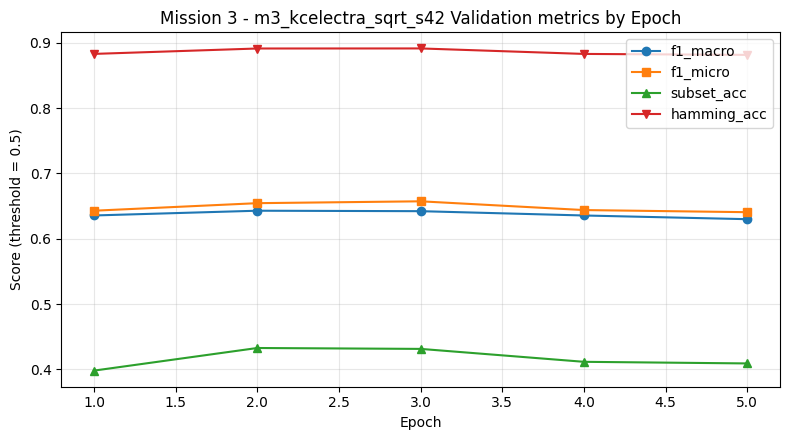

In [4]:
# ===== epoch별 Validation 지표 그래프 (저장된 history CSV 기준, 몇 번 실행해도 같은 결과) =====
import matplotlib.pyplot as plt

PLOT_RUN_NAME = "m3_kcelectra_sqrt_s42"  # 보고 싶은 실행 이름으로 교체
h = pd.read_csv(os.path.join(CONFIG["history_dir"], f"{PLOT_RUN_NAME}_history.csv"))

plt.figure(figsize=(8, 4.5))
for col, marker in [("f1_macro", "o"), ("f1_micro", "s"), ("subset_acc", "^"), ("hamming_acc", "v")]:
    plt.plot(h["epoch"], h[col], marker=marker, label=col)
plt.xlabel("Epoch")
plt.ylabel("Score (threshold = 0.5)")
plt.title(f"Mission 3 - {PLOT_RUN_NAME} Validation metrics by Epoch")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(f"/content/{PLOT_RUN_NAME}_metrics.png", dpi=150)
plt.show()


[val] 캐시에서 불러옴: /content/drive/MyDrive/DCC/mission3_v4/cache/parsed_val.pkl


Loading weights:   0%|          | 0/197 [00:01<?, ?it/s]

[transformers] ElectraModel LOAD REPORT from: /content/drive/MyDrive/DCC/mission3_v3/ckpt/m3_kcelectra_base_s42_best
Key                        | Status     |  | 
---------------------------+------------+--+-
classifier.dense.bias      | UNEXPECTED |  | 
classifier.dense.weight    | UNEXPECTED |  | 
classifier.out_proj.bias   | UNEXPECTED |  | 
classifier.out_proj.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


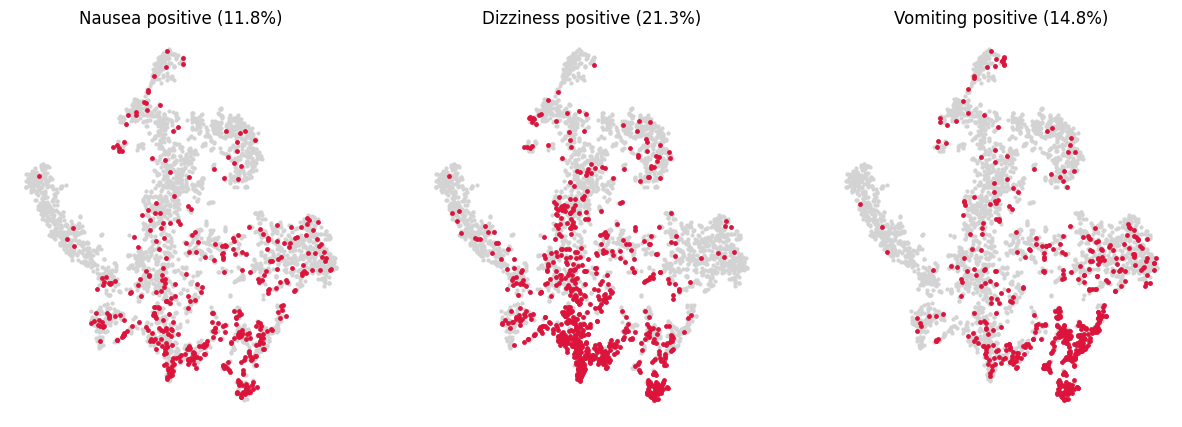

오심: 기준율 0.118 / 이웃 10개 중 같은 라벨 0.221
어지러움: 기준율 0.213 / 이웃 10개 중 같은 라벨 0.545
구토: 기준율 0.148 / 이웃 10개 중 같은 라벨 0.432


In [6]:
import os, numpy as np, torch, matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from transformers import AutoTokenizer, AutoModel

val_df = load_or_build("val")          # 노트북의 데이터 로드 함수 (3,640행)
MODEL_DIR = "/content/drive/MyDrive/DCC/mission3_v3/ckpt/m3_kcelectra_base_s42_best"  # 실제 폴더명 확인
LABELS = TEAM_LABELS

tok = AutoTokenizer.from_pretrained(MODEL_DIR)
enc_model = AutoModel.from_pretrained(MODEL_DIR).half().cuda().eval()

texts = val_df["text"].tolist()
embs = []
with torch.no_grad():
    for i in range(0, len(texts), 32):
        b = tok(texts[i:i+32], truncation=True, max_length=512, padding=True,
                return_tensors="pt", return_token_type_ids=False).to("cuda")
        embs.append(enc_model(**b).last_hidden_state[:, 0].float().cpu().numpy())  # [CLS] 임베딩
E = np.concatenate(embs)
Y = np.array([[l in s for l in LABELS] for s in val_df["symptoms"]])

# 1) t-SNE: 오심 / 어지러움 / 구토 양성을 각각 빨강으로 표시
Z = TSNE(n_components=2, perplexity=30, init="pca", random_state=42).fit_transform(E)
names = {"오심": "Nausea", "어지러움": "Dizziness", "구토": "Vomiting"}  # 한글 폰트 깨짐 방지
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, k in zip(axes, names):
    pos = Y[:, LABELS.index(k)]
    ax.scatter(Z[~pos, 0], Z[~pos, 1], s=4, c="lightgray")
    ax.scatter(Z[pos, 0], Z[pos, 1], s=6, c="crimson")
    ax.set_title(f"{names[k]} positive ({pos.mean()*100:.1f}%)"); ax.axis("off")
plt.show()

# 2) 수치 근거: 양성 샘플의 이웃 10개 중 같은 라벨 비율 vs 기준율
En = E / np.linalg.norm(E, axis=1, keepdims=True)
idx = NearestNeighbors(n_neighbors=11, metric="cosine").fit(En).kneighbors(En, return_distance=False)[:, 1:]
for k in names:
    j = LABELS.index(k); pos = Y[:, j]
    print(f"{k}: 기준율 {pos.mean():.3f} / 이웃 10개 중 같은 라벨 {Y[idx[pos], j].mean():.3f}")